# Corn store-or-sell: the whole process, step by step

**The question.** On **October 15**, should a Central Illinois corn holder **store the corn until April 15**,
hedged by selling May corn futures, or **sell now and put the cash in 6-month T-bills**? With the hedge in
place, storing pays only if the gap between May futures and the local cash price narrows by more than the
storage cost plus the T-bill interest given up. This notebook follows every step, from the raw files to an
out-of-sample test.

**How to read it.** Every step follows the same pattern: **table in → main code + explanation → table out**.
The code is the real logic from the numbered scripts in `notebooks/` (shortened where noted), re-run here so you
can see each table change. Each result is then checked against the file the script saved.

*Read-only: every cell only **reads** files. Nothing in `data/`, the scripts, `docs/` or `outputs/` is changed.
Plan: [README](../README.md). Every decision: [processing log](../docs/processing_log.md). Column meanings:
[data dictionary](../docs/data_dictionary.md).*

## Pipeline map

| Source | Raw file (`data/raw/`) | Script | Clean file | Used in |
|---|---|---|---|---|
| USDA MyMarketNews report 3192, Illinois Grain Bids (API, one month per pull) | `3192_YYYY-MM.csv` (12 Oct/Apr files) | `03_build_silver.py` | `data/clean/corn_bids_current.csv` | `06` → table `corn_bids` → `07` (Oct and Apr cash price) |
| CBOT May corn settlements, typed by hand from Barchart | `may_futures.csv` | `04_clean_futures.py` | `data/clean/may_futures.csv` | `06` → table `may_futures` → `07` (hedge prices) |
| FRED series DTB6, 6-month T-bill (download) | `fred_dtb6.csv` | `05_tbill_rates.py` | `data/clean/tbill_decision.csv` | `06` → table `tbill_decision` → `07` (interest) |
| farmdoc daily (commercial) and Iowa Farm Bureau (on-farm), typed by hand | `storage_costs.csv` | none | none (read directly) | `07` (storage cases) |
| the 3 clean CSVs | | `06_build_db.py` | `data/clean/corn.db` (SQLite) | `07` |
| `corn.db` + `storage_costs.csv` | | `07_build_gold.py` | `data/gold/gold_yearly.csv` + table `gold_yearly` | `08`, `09` |
| `gold_yearly.csv` | | `08_charts.py` | `outputs/scatter_gap.png`, `outputs/bars_by_year.png` | Part 4 |
| `gold_yearly.csv` | | `09_walk_forward.py` | `outputs/walk_forward_predictions.csv`, `outputs/scoreboard.csv` | Part 5 |

**Run order:** `03` → `04` → `05` → `06` → `07` → `08` → `09`.
`06` rebuilds `corn.db` from scratch (with `--overwrite`), which also removes the gold table, so `07` must always run after it.

## Setup

Imports, paths and file loading all happen here, once. `show(df, name)` prints a table's shape, its first 5 rows and
its missing values per column; `change(raw, clean)` prints the one-line before/after summary used in Part 1.
Nothing here writes a file: the database is opened **read-only** (`mode=ro`).

In [1]:
from pathlib import Path
import re
import sqlite3
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()                                    # find the project folder, so this runs from anywhere
while not (ROOT / "notebooks/09_walk_forward.py").exists():
    ROOT = ROOT.parent
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)
CASES = ("low", "mid", "high")                       # the three storage-cost cases

def n_missing(df):
    """Missing cells per column: NaN, or a blank string (files read as text)."""
    return (df.isna() | df.astype(str).apply(lambda s: s.str.strip().eq(""))).sum()

def show(df, name, n=5):
    """Shape, first n rows, and missing values per column."""
    miss = n_missing(df)
    print(f"{name}: {df.shape[0]:,} rows x {df.shape[1]} columns")
    display(df.head(n))
    print("missing per column:", "none" if miss.sum() == 0 else miss[miss > 0].to_dict())

def change(raw, clean, log):
    """One-line raw -> clean summary, next to the processing log's Raw vs Clean numbers."""
    print(f"rows {len(raw):,} → {len(clean):,}, columns {raw.shape[1]} → {clean.shape[1]}, "
          f"missing {n_missing(raw).sum():,} → {n_missing(clean).sum():,}   (processing log: {log})")

# Raw files: data/raw/ is evidence, only read
BID_MONTHS = ["2020-10", "2021-04", "2021-10", "2022-04", "2022-10", "2023-04",
              "2023-10", "2024-04", "2024-10", "2025-04", "2025-10", "2026-04"]
raw_bid_files = {ym: pd.read_csv(ROOT / f"data/raw/3192_{ym}.csv") for ym in BID_MONTHS}
raw_futures = pd.read_csv(ROOT / "data/raw/may_futures.csv", dtype=str, keep_default_na=False)
raw_fred = pd.read_csv(ROOT / "data/raw/fred_dtb6.csv", dtype=str, keep_default_na=False)
storage = pd.read_csv(ROOT / "data/raw/storage_costs.csv")

# Files the scripts saved: used to check that this notebook reproduces them exactly
CLEAN = ["corn_bids_current", "may_futures", "tbill_decision"]
clean_text = {t: (ROOT / f"data/clean/{t}.csv").read_text() for t in CLEAN}
clean_csv = {t: pd.read_csv(ROOT / f"data/clean/{t}.csv", dtype=str, keep_default_na=False) for t in CLEAN}
gold_text = (ROOT / "data/gold/gold_yearly.csv").read_text()
gold_cols = pd.read_csv(ROOT / "data/gold/gold_yearly.csv", nrows=0).columns.tolist()
scoreboard_file = pd.read_csv(ROOT / "outputs/scoreboard.csv")
con = sqlite3.connect(f"file:{ROOT / 'data/clean/corn.db'}?mode=ro", uri=True)   # read-only

# Part 1: Clean each source

Four sources feed the decision. Each one gets the same three parts: **a) raw table**, **b) main code**, **c) clean table**,
then one line: rows, columns and missing values before → after.

## 1.1 Cash bids (`03_build_silver.py`)

**a) Raw table.** USDA report 3192 lists every Illinois grain bid: corn, soybeans and wheat, by region, by buyer type,
for delivery now and for later. The 12 monthly pulls (October and April, 2020-10 to 2026-04) are stacked into one table,
as in `03_build_silver.py` **line 53**. The second table counts rows by commodity and delivery, to show how much is not needed.

In [2]:
raw_bids = pd.concat(raw_bid_files.values(), ignore_index=True)   # 03 line 53: stack the 12 monthly pulls
show(raw_bids, "raw report 3192, 12 files stacked")
display(raw_bids.groupby(["commodity", "current"]).size().unstack())   # current = "deliver now?"

raw report 3192, 12 files stacked: 12,486 rows x 55 columns


,report_date,report_begin_date,report_end_date,published_date,office_name,office_city,office_state,market_type,market_location_name,market_location_city,market_location_state,slug_id,slug_name,report_title,grp,...,price Min,price Max,price Min Change,price Min Direction,price Max Change,price Max Direction,avg_price,avg_price_year_ago,freight,trans_mode,current,delivery_start,delivery Start Half,delivery_end,delivery End Half
0,10/30/2020,10/30/2020,10/30/2020,10/30/2020 14:58:14,"Springfield, IL",Springfield,IL,Point of Sale - Grain,Grain - Illinois,Springfield,IL,3192,AMS_3192,Illinois Grain Bids,Grains,...,10.5325,10.6125,0.0025,DN,0.0375,UP,10.5654,NaN,Delivered,Truck,No,2021-01-01,NaN,2021-01-01,NaN
1,10/30/2020,10/30/2020,10/30/2020,10/30/2020 14:58:14,"Springfield, IL",Springfield,IL,Point of Sale - Grain,Grain - Illinois,Springfield,IL,3192,AMS_3192,Illinois Grain Bids,Grains,...,10.1950,10.4450,0.1225,DN,0.1225,DN,10.3717,NaN,Delivered,Truck,Yes,NaN,NaN,NaN,NaN
2,10/30/2020,10/30/2020,10/30/2020,10/30/2020 14:58:14,"Springfield, IL",Springfield,IL,Point of Sale - Grain,Grain - Illinois,Springfield,IL,3192,AMS_3192,Illinois Grain Bids,Grains,...,10.5925,10.6625,0.0575,UP,0.0175,UP,10.6305,NaN,Delivered,Truck,No,2021-01-01,NaN,2021-01-01,NaN
3,10/30/2020,10/30/2020,10/30/2020,10/30/2020 14:58:14,"Springfield, IL",Springfield,IL,Point of Sale - Grain,Grain - Illinois,Springfield,IL,3192,AMS_3192,Illinois Grain Bids,Grains,...,10.3250,10.5750,0.0625,DN,0.0475,UP,10.3990,NaN,Delivered,Truck,Yes,NaN,NaN,NaN,NaN
4,10/30/2020,10/30/2020,10/30/2020,10/30/2020 14:58:14,"Springfield, IL",Springfield,IL,Point of Sale - Grain,Grain - Illinois,Springfield,IL,3192,AMS_3192,Illinois Grain Bids,Grains,...,10.5025,10.9125,0.0475,UP,0.0475,UP,10.6585,NaN,Delivered,Truck,No,2021-01-01,NaN,2021-01-01,NaN


missing per column: {'location_State': 12486, 'location_City': 12486, 'class': 5615, 'protein': 11401, 'application': 12486, 'desc': 12465, 'basis_unit': 21, 'basis Min': 21, 'basis Min Futures Month': 21, 'basis Max': 21, 'basis Max Futures Month': 21, 'basis Min Change': 332, 'basis Min Direction': 313, 'basis Max Change': 332, 'basis Max Direction': 313, 'price Min': 21, 'price Max': 21, 'price Min Change': 208, 'price Min Direction': 189, 'price Max Change': 208, 'price Max Direction': 189, 'avg_price': 21, 'avg_price_year_ago': 3168, 'delivery_start': 6251, 'delivery Start Half': 11885, 'delivery_end': 6251, 'delivery End Half': 11885}


current,No,Yes
commodity,,
Corn,2754,3032
Soybeans,2689,2926
Wheat,792,293


**b) Main code.** `03_build_silver.py` **lines 31-47** (column lists) and **lines 55-85** (filter, rename, convert, check).

- **What:** keep 13 of the 55 columns; keep **corn** bids for **current delivery** only; rename USDA's columns to project
  names; turn `Yes`/`No` into `True`/`False`; read `MM/DD/YYYY` as a real date; drop 8 empty `¢/Bu` rows; check the primary key.
- **Why:** the question is about selling corn *now* (spot) versus later, so forward bids and other grains are not needed.
  The 8 dropped rows (South Illinois River, barge elevators, Oct 2022) have no price, and each one repeats the key of a real
  `$ Per Bushel` row, so dropping them loses no price. After that, (`date`, `region`, `buyer_type`) must be unique: one bid
  per region, buyer type and day.
- **Shortened:** the script's printed summary and save step are left out.

In [3]:
KEEP = ["report_date", "commodity", "trade_loc", "delivery_point", "current", "avg_price",
        "price Min", "price Max", "price_unit", "class", "grade", "freight", "trans_mode"]
RENAME = {"report_date": "date", "trade_loc": "region", "delivery_point": "buyer_type",
          "current": "deliver_now", "avg_price": "cash_price", "price Min": "cash_price_low",
          "price Max": "cash_price_high", "class": "grain_class", "grade": "grain_grade",
          "freight": "price_point", "trans_mode": "transport_mode"}
PRICE_COLS = ["cash_price", "cash_price_low", "cash_price_high"]

df = raw_bids[KEEP].copy()                                               # 13 of 55 columns
df = df[(df["commodity"] == "Corn") & (df["current"] == "Yes")]          # corn, deliver-now bids only
df = df.rename(columns=RENAME)                                           # USDA names -> project names
df["deliver_now"] = df["deliver_now"].map({"Yes": True, "No": False})    # Yes/No -> True/False
df["date"] = pd.to_datetime(df["date"], format="%m/%d/%Y")               # USDA MM/DD/YYYY -> real date

empty_cents = (df["price_unit"] == "¢/Bu") & df[PRICE_COLS].isna().all(axis=1)   # no price at all
assert empty_cents.sum() == 8                                            # exactly the 8 known rows
dropped = df[empty_cents]                                                # kept aside to look at below
df = df[~empty_cents]                                                    # drop them; no price is lost

PK = ["date", "region", "buyer_type"]                                    # primary key
assert df.duplicated(PK).sum() == 0, "duplicate primary key"             # one bid per key
assert df[PK].notna().all().all(), "blank key value"
bids = df.sort_values(PK).reset_index(drop=True)                         # sorted by the key
display(dropped[["date", "region", "buyer_type", "price_unit", "cash_price"]])

,date,region,buyer_type,price_unit,cash_price
4612,2022-10-13,South Illinois River,Barge Loading Elevators,¢/Bu,NaN
4664,2022-10-12,South Illinois River,Barge Loading Elevators,¢/Bu,NaN
4716,2022-10-11,South Illinois River,Barge Loading Elevators,¢/Bu,NaN
4768,2022-10-07,South Illinois River,Barge Loading Elevators,¢/Bu,NaN
4819,2022-10-06,South Illinois River,Barge Loading Elevators,¢/Bu,NaN
4870,2022-10-05,South Illinois River,Barge Loading Elevators,¢/Bu,NaN
4922,2022-10-04,South Illinois River,Barge Loading Elevators,¢/Bu,NaN
4973,2022-10-03,South Illinois River,Barge Loading Elevators,¢/Bu,NaN


**c) Clean table.** One row = one region's corn bid from one buyer type on one day. The last line checks that this
notebook's table is **byte-for-byte identical** to the file `03` saved (`data/clean/corn_bids_current.csv`).

In [4]:
show(bids, "clean corn_bids_current")
change(raw_bids, bids, log="12,486 × 55 → 3,024 × 13")
same = bids.to_csv(index=False, na_rep="MISSING", date_format="%Y-%m-%d") == clean_text["corn_bids_current"]
print("identical to data/clean/corn_bids_current.csv:", same)

clean corn_bids_current: 3,024 rows x 13 columns


,date,commodity,region,buyer_type,deliver_now,cash_price,cash_price_low,cash_price_high,price_unit,grain_class,grain_grade,price_point,transport_mode
0,2020-10-01,Corn,Central,Mills and Processors,True,3.7192,3.5475,3.7975,$ Per Bushel,Yellow,US #2,Delivered,Truck
1,2020-10-01,Corn,Chicago,Mills and Processors,True,3.8875,3.8175,3.9575,$ Per Bushel,Yellow,US #2,Delivered,Truck
2,2020-10-01,Corn,Chicago,Terminal Elevators,True,3.5275,3.3775,3.6775,$ Per Bushel,Yellow,US #2,Delivered,Truck
3,2020-10-01,Corn,Little Egypt,Country Elevators,True,3.7895,3.6675,3.9475,$ Per Bushel,Yellow,US #2,Delivered,Truck
4,2020-10-01,Corn,North,Country Elevators,True,3.5755,3.4775,3.6275,$ Per Bushel,Yellow,US #2,Delivered,Truck


missing per column: none
rows 12,486 → 3,024, columns 55 → 13, missing 108,631 → 0   (processing log: 12,486 × 55 → 3,024 × 13)
identical to data/clean/corn_bids_current.csv: True


Rows dropped: 6,700 not corn + 2,754 corn for later delivery + 8 empty `¢/Bu` rows = 9,462 (matches the log).
The raw missing cells are in columns that are not kept, or in rows that are filtered out; the clean table has none.
*Details:* [processing log: 03_build_silver.py: cash bids (silver table)](../docs/processing_log.md#03_build_silverpy-cash-bids-silver-table)

## 1.2 May futures (`04_clean_futures.py`)

**a) Raw table.** 12 settlement prices of the CBOT May corn contract: for each decision year, one on the October date
(sell futures = open the hedge) and one on the April date (buy back = close the hedge), always on the **same** May contract.
They were typed by hand from Barchart exactly as quoted, in **cents and eighths**. The file is read as text so nothing is reinterpreted.

In [5]:
show(raw_futures, "raw may_futures.csv")

raw may_futures.csv: 12 rows x 5 columns


,decision_year,date,contract,settle_raw,source
0,2020,2020-10-15,ZCK21,409-2,Barchart settlement
1,2020,2021-04-15,ZCK21,590-0,Barchart settlement
2,2021,2021-10-15,ZCK22,538-6,Barchart settlement
3,2021,2022-04-14,ZCK22,790-2,Barchart settlement
4,2022,2022-10-14,ZCK23,697-2,Barchart settlement


missing per column: none


**b) Main code.** `04_clean_futures.py` **lines 26-61**.

- **What:** rename `contract`; spell the contract code out in words; label each row as the Oct (open) or Apr (close) leg;
  convert the quote to **$/bushel**.
- **Why:** `583-2` means 583 and **2/8** cents = 583.25¢ = **$5.8325**. Reading it as 583.2 would be wrong, so the
  format is checked strictly (a dash, then an eighth from 0 to 7) and anything else stops the script. Values are not rounded:
  odd eighths need 5 decimals (`583-1` = $5.83125). A blank quote would stay blank (MISSING), never guessed; there are none.

In [6]:
df = raw_futures.rename(columns={"contract": "futures_contract"})         # clearer column name

def contract_name(code):                                                  # "ZCK21" -> "May 2021 corn"
    m = re.fullmatch(r"ZC([A-Z])(\d{2})", code)                            # ZC = corn, K = May, 21 = 2021
    if not m or m.group(1) != "K":
        raise ValueError(f"Unexpected contract code: {code}")              # only May contracts expected
    return f"May 20{m.group(2)} corn"
df["contract_name"] = df["futures_contract"].map(contract_name)

LEGS = {10: "Oct (open hedge)", 4: "Apr (close hedge)"}                  # month -> hedge leg
df["leg"] = pd.to_datetime(df["date"]).dt.month.map(LEGS)

def to_dollars(raw):                                                      # cents and eighths -> $/bu
    if raw.strip() == "":
        return None                                                       # blank stays MISSING
    m = re.fullmatch(r"(\d+)-([0-7])", raw.strip())                        # strict: 583-2, eighths 0-7
    if not m:
        raise ValueError(f"Unexpected settle_raw format: {raw!r}")
    return (int(m.group(1)) + int(m.group(2)) / 8) / 100                  # 583 + 2/8 = 583.25¢ -> $5.8325
df["may_futures_price"] = df["settle_raw"].map(to_dollars).astype(float)

futures = df[["decision_year", "date", "futures_contract", "contract_name", "leg",
              "settle_raw", "source", "may_futures_price"]]               # fixed column order
print("583-2 ->", to_dollars("583-2"), "   583-1 ->", to_dollars("583-1"))

583-2 -> 5.8325    583-1 -> 5.83125


**c) Clean table.** Same 12 rows, 3 new columns. The second table lists the hedge dates that are **not** the 15th: when
Oct 15 or Apr 15 was not a trading day, the nearest **prior** trading day was used (README rule), so no later price is used.

In [7]:
show(futures, "clean may_futures")
change(raw_futures, futures, log="12 × 5 → 12 × 8")
print("identical to data/clean/may_futures.csv:", futures.to_csv(index=False) == clean_text["may_futures"])
display(futures.loc[~futures["date"].str.endswith("-15"), ["decision_year", "date", "leg", "settle_raw", "may_futures_price"]])

clean may_futures: 12 rows x 8 columns


,decision_year,date,futures_contract,contract_name,leg,settle_raw,source,may_futures_price
0,2020,2020-10-15,ZCK21,May 2021 corn,Oct (open hedge),409-2,Barchart settlement,4.0925
1,2020,2021-04-15,ZCK21,May 2021 corn,Apr (close hedge),590-0,Barchart settlement,5.9000
2,2021,2021-10-15,ZCK22,May 2022 corn,Oct (open hedge),538-6,Barchart settlement,5.3875
3,2021,2022-04-14,ZCK22,May 2022 corn,Apr (close hedge),790-2,Barchart settlement,7.9025
4,2022,2022-10-14,ZCK23,May 2023 corn,Oct (open hedge),697-2,Barchart settlement,6.9725


missing per column: none
rows 12 → 12, columns 5 → 8, missing 0 → 0   (processing log: 12 × 5 → 12 × 8)
identical to data/clean/may_futures.csv: True


,decision_year,date,leg,settle_raw,may_futures_price
3,2021,2022-04-14,Apr (close hedge),790-2,7.9025
4,2022,2022-10-14,Oct (open hedge),697-2,6.9725
5,2022,2023-04-14,Apr (close hedge),666-2,6.6625
6,2023,2023-10-13,Oct (open hedge),516-4,5.1650


*Details:* [processing log: 04_clean_futures.py: May futures](../docs/processing_log.md#04_clean_futurespy-may-futures)

## 1.3 T-bill rate (`05_tbill_rates.py`)

**a) Raw table.** FRED series DTB6: the daily 6-month T-bill rate in **percent**, from 1958 on. Bond-market holidays
appear as blank rows.

In [8]:
show(raw_fred, "raw fred_dtb6.csv")
print("last date:", raw_fred["observation_date"].max())

raw fred_dtb6.csv: 17,707 rows x 2 columns


,observation_date,DTB6
0,1958-12-09,3.09
1,1958-12-10,3.07
2,1958-12-11,3.06
3,1958-12-12,3.04
4,1958-12-15,3.03


missing per column: {'DTB6': 755}
last date: 2026-10-21


**b) Main code.** `05_tbill_rates.py` **lines 24-51**.

- **What:** drop the blank holiday rows; for each of the 6 decision dates D, average DTB6 over the **10 calendar days
  D-9 to D** (D included); keep the rate as text (`4.02%`) for reading and as a **decimal** for calculations.
- **Why:** the rate prices the opportunity cost of waiting: the T-bill interest a farmer gives up by holding corn
  instead of cash. A 10-day average smooths one-day jumps. Only dates up to D are used (**no future leakage**): the farmer
  can buy a T-bill at the market rate on D itself. Blank days are skipped, never filled.
- **Shortened:** the MISSING branch (when a window has no data; it never happens) and the single-day comparison print are left out.

In [9]:
DECISION_DATES = ["2020-10-15", "2021-10-15", "2022-10-14",      # the Oct dates of may_futures
                  "2023-10-13", "2024-10-15", "2025-10-15"]      # (prior trading day where needed)

fred = raw_fred.copy()
fred["observation_date"] = pd.to_datetime(fred["observation_date"])
fred = fred[fred["DTB6"].str.strip() != ""].copy()               # drop holiday blanks (not filled)
fred["DTB6"] = fred["DTB6"].astype(float)                        # percent, e.g. 4.02

rows = []
for d in pd.to_datetime(DECISION_DATES):
    start = d - pd.Timedelta(days=9)                             # 10 calendar days: D-9 .. D
    win = fred[(fred["observation_date"] >= start) & (fred["observation_date"] <= d)]
    assert win["observation_date"].max() <= d, "date after decision date used"   # no leakage
    avg = win["DTB6"].mean()                                     # average of the published days
    rows.append({"decision_year": d.year, "decision_date": d.strftime("%Y-%m-%d"),
                 "window_start": start.strftime("%Y-%m-%d"), "window_end": d.strftime("%Y-%m-%d"),
                 "n_days_used": len(win),                        # weekends/holidays have no rate
                 "dtb6_avg_pct": f"{avg:.2f}%",                  # for reading
                 "rate_decimal": avg / 100})                     # percent -> decimal, for calculations
tbill = pd.DataFrame(rows)
assert not tbill["decision_date"].duplicated().any()             # primary key: decision_date

**c) Clean table.** One row per decision date. 2024 used only 6 days because 2024-10-14 is blank in FRED.

In [10]:
show(tbill, "clean tbill_decision", n=6)
change(raw_fred, tbill, log="17,707 × 2 → 6 × 7; 755 blank holiday rows skipped")
print("identical to data/clean/tbill_decision.csv:", tbill.to_csv(index=False) == clean_text["tbill_decision"])

clean tbill_decision: 6 rows x 7 columns


,decision_year,decision_date,window_start,window_end,n_days_used,dtb6_avg_pct,rate_decimal
0,2020,2020-10-15,2020-10-06,2020-10-15,7,0.12%,0.001186
1,2021,2021-10-15,2021-10-06,2021-10-15,7,0.06%,0.000614
2,2022,2022-10-14,2022-10-05,2022-10-14,7,4.02%,0.040229
3,2023,2023-10-13,2023-10-04,2023-10-13,7,5.33%,0.053343
4,2024,2024-10-15,2024-10-06,2024-10-15,6,4.30%,0.042983
5,2025,2025-10-15,2025-10-06,2025-10-15,7,3.70%,0.037043


missing per column: none
rows 17,707 → 6, columns 2 → 7, missing 755 → 0   (processing log: 17,707 × 2 → 6 × 7; 755 blank holiday rows skipped)
identical to data/clean/tbill_decision.csv: True


*Details:* [processing log: 05_tbill_rates.py: T-bill rate for the hurdle](../docs/processing_log.md#05_tbill_ratespy-t-bill-rate-for-the-hurdle)

## 1.4 Storage costs (`data/raw/storage_costs.csv`, no script)

**a) Raw table.** The cost of physically storing a bushel from Oct 15 to Apr 15, typed by hand from articles
(user-approved 2026-11-13), one row per decision year, in **three cases**:

| Case | What it represents | Source | Value (cents/bu, 6 months) |
|---|---|---|---|
| **low** | on-farm bins | Iowa Farm Bureau (2016, figure not attributed): 1-2¢/bu/month, midpoint 1.5¢ × 6. **Weaker source**, same every year | 9 |
| **high** | commercial elevator | farmdoc daily, Zulauf, Paulson & Janzen (Oct 2, 2025): "physical storage" $/bu/year × 0.5 (one Ohio country elevator) | 35.5 to 65 |
| **mid** | in between | (low + high) / 2 | 22.25 to 37 |

Only physical storage is used, not total storage cost, because interest is already counted from the T-bill rate.

In [11]:
show(storage, "raw storage_costs.csv", n=6)

raw storage_costs.csv: 6 rows x 7 columns


,decision_year,storage_low_cents,storage_mid_cents,storage_high_cents,source_url_low,source_url_high,note
0,2020,9.0,22.25,35.5,https://www.iowafarmbureau.com/Article/Keep-a-...,https://farmdocdaily.illinois.edu/2025/10/annu...,low: typed from article (on-farm 1.5 c/bu/mont...
1,2021,9.0,22.50,36.0,https://www.iowafarmbureau.com/Article/Keep-a-...,https://farmdocdaily.illinois.edu/2025/10/annu...,low: typed from article (on-farm 1.5 c/bu/mont...
2,2022,9.0,22.50,36.0,https://www.iowafarmbureau.com/Article/Keep-a-...,https://farmdocdaily.illinois.edu/2025/10/annu...,low: typed from article (on-farm 1.5 c/bu/mont...
3,2023,9.0,37.00,65.0,https://www.iowafarmbureau.com/Article/Keep-a-...,https://farmdocdaily.illinois.edu/2025/10/annu...,low: typed from article (on-farm 1.5 c/bu/mont...
4,2024,9.0,37.00,65.0,https://www.iowafarmbureau.com/Article/Keep-a-...,https://farmoffice.osu.edu/blog/mon-10062025-4...,low: typed from article (on-farm 1.5 c/bu/mont...
5,2025,9.0,37.00,65.0,https://www.iowafarmbureau.com/Article/Keep-a-...,https://farmoffice.osu.edu/blog/mon-10062025-4...,low: typed from article (on-farm 1.5 c/bu/mont...


missing per column: none


**b) Main code.** `07_build_gold.py` **lines 70-75**: the checks `07` runs before using this file. There is no
cleaning step: the file is already in cents for the 6-month hold, so `07` reads it directly and copies the three cost
columns into the gold table (Part 3).

- **Why the checks:** exactly one row per decision year 2020-2025 (so the join in Part 3 cannot duplicate or lose a year),
  and `mid` must really be the average of `low` and `high` (catches a typing error).

In [12]:
assert sorted(storage["decision_year"]) == list(range(2020, 2026)), "need one row per year 2020-2025"
assert not storage["decision_year"].duplicated().any(), "duplicate year"
mid_gap = ((storage["storage_low_cents"] + storage["storage_high_cents"]) / 2 - storage["storage_mid_cents"]).abs()
assert mid_gap.max() < 1e-9, "mid is not (low + high) / 2"            # catches a typing error
print("checks passed: one row per year, mid = (low + high) / 2, missing:", int(n_missing(storage).sum()))
print("\n2025 note:", storage.loc[storage["decision_year"] == 2025, "note"].item())

checks passed: one row per year, mid = (low + high) / 2, missing: 0

2025 note: low: typed from article (on-farm 1.5 c/bu/month x 6; weaker source, Iowa Farm Bureau 2016, unattributed). high: FLAG no 2025 value published; 2024 physical storage 1.30 $/bu/yr carried forward x 0.5. mid = (low + high) / 2


**c) "Clean" table.** None: rows 6 → 6 (no clean copy), columns 7 → 3 used (`storage_low/mid/high_cents`), missing 0 → 0
(processing log: 6 × 7, "read directly by `07`; no clean copy").

> **Flag:** the **2025 high** value (65¢) is the 2024 value **carried forward**, because farmdoc had not published a
> 2025 figure. It is a placeholder, not a measured number.

Known limits: halving the yearly commercial cost probably **understates** it (elevators often charge a flat fee and then
a monthly rate; about 68% of the yearly cost under 2014 central-Illinois rates), and the rate comes from Ohio, not Illinois.
*Details:* [processing log: 2026-11-13: storage cost cases added to gold (06 → 07 → 08 rerun)](../docs/processing_log.md#2026-11-13-storage-cost-cases-added-to-gold-06--07--08-rerun)

# Part 2: Database (`06_build_db.py`)

`06` loads the three clean CSVs into one SQLite file, `data/clean/corn.db`, and adds a `calendar` table: every day
from 2020-01-01 to 2026-12-31. Keys make the database itself refuse bad data.

- A **primary key (PK)** is the column(s) that identify a row, so they can never repeat: in `corn_bids` it is
  (`date`, `region`, `buyer_type`), so two different prices for North Central country elevators on the same day cannot both exist.
- A **foreign key (FK)** says a value must already exist in another table: every `date` in `corn_bids` must be a real
  day in `calendar`, so a typo like `2022-02-30` is rejected instead of silently joining to nothing.

**Tables and keys, as read from the database itself:**

In [13]:
TABLES = ["calendar", "corn_bids", "may_futures", "tbill_decision", "gold_yearly"]   # gold_yearly: added by 07
keys = []
for t in TABLES:
    info = con.execute(f"PRAGMA table_info({t})").fetchall()                  # (cid, name, type, notnull, default, pk)
    pk = [c[1] for c in sorted(info, key=lambda c: c[5]) if c[5] > 0]          # PK columns, in key order
    fk = [f"{f[3]} → {f[2]}({f[4]})" for f in con.execute(f"PRAGMA foreign_key_list({t})")]
    keys.append({"table": t, "rows": con.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0],
                 "primary key": ", ".join(pk), "foreign keys": "; ".join(fk) or "none"})
display(pd.DataFrame(keys))

,table,rows,primary key,foreign keys
0,calendar,2557,date,none
1,corn_bids,3024,"date, region, buyer_type",date → calendar(date)
2,may_futures,12,date,date → calendar(date)
3,tbill_decision,6,decision_date,decision_date → calendar(date)
4,gold_yearly,12,"decision_year, region",apr_date → calendar(date); oct_date → calendar...


**Main code.** `06_build_db.py` **lines 70-78** (which key goes with which table), **lines 95-120** (checks before
loading) and **lines 143-144** (SQLite's own check after loading).

- **What:** build the calendar; then for each clean CSV count duplicate PKs, blank PK values and FK dates that are not in
  the calendar. All three must be 0, otherwise `06` prints the problem rows, stops and saves nothing.
- **Why:** checking *before* loading means a bad file never reaches the database. SQLite's `foreign_key_check` is a
  second, independent check after loading (it returns an empty list when every FK is valid).
- **Note:** foreign keys are **off by default** in SQLite; `06` turns them on with `PRAGMA foreign_keys = ON`.

In [14]:
calendar = pd.date_range("2020-01-01", "2026-12-31", freq="D").strftime("%Y-%m-%d")   # every day
cal_set = set(calendar)
assert not pd.Series(calendar).duplicated().any()                         # calendar PK is unique
KEYS = {"corn_bids": ("corn_bids_current", ["date", "region", "buyer_type"], "date"),   # table: (csv, PK, FK)
        "may_futures": ("may_futures", ["date"], "date"),
        "tbill_decision": ("tbill_decision", ["decision_date"], "decision_date")}
checks = []
for t, (csv, pk, fk) in KEYS.items():
    df = clean_csv[csv]                                                   # read as text, like 06
    checks.append({"table": t, "rows": len(df),
                   "duplicate PKs": int(df.duplicated(pk, keep=False).sum()),   # must be 0
                   "blank PK values": int((df[pk] == "").any(axis=1).sum()),    # must be 0
                   "FK dates not in calendar": int((~df[fk].isin(cal_set)).sum())})  # must be 0
display(pd.DataFrame(checks))
print("calendar rows:", len(calendar))
print("SQLite foreign_key_check:", con.execute("PRAGMA foreign_key_check").fetchall())   # [] = no violations

,table,rows,duplicate PKs,blank PK values,FK dates not in calendar
0,corn_bids,3024,0,0,0
1,may_futures,12,0,0,0
2,tbill_decision,6,0,0,0


calendar rows: 2557
SQLite foreign_key_check: []


All counts are 0 and SQLite's check is empty, so every price and rate sits on a real date with a unique key.
Row counts match the log (calendar 2,557, corn_bids 3,024, may_futures 12, tbill_decision 6).
*Details:* [processing log: 06_build_db.py: SQLite database](../docs/processing_log.md#06_build_dbpy-sqlite-database)

# Part 3: Gold table (`07_build_gold.py`)

The gold table holds everything needed to judge "store or sell": **one row per region per decision year**. It uses
**Country Elevators** (the buyers a farmer actually delivers to) in **North Central** and **South Central** Illinois,
decision years 2020-2025: 2 × 6 = 12 rows.

**Input tables:** `may_futures` (Oct and Apr hedge prices), `corn_bids` (cash price on the same dates),
`tbill_decision` (rate on the Oct date), and `storage_costs.csv` (cost cases by year).

### Join 1: one "leg" per hedge date

`07_build_gold.py` **lines 45-61**. For each futures row of one leg (Oct or Apr), take both regions and look up the
cash bid on the **same date**. A `LEFT JOIN` keeps the row even if a bid is missing (it would show up as blank and stop the
script later), instead of silently dropping it. The columns are renamed with an `oct_` or `apr_` prefix.

In [15]:
REGIONS, BUYER_TYPE = ("North Central", "South Central"), "Country Elevators"
LEG_SQL = """
SELECT f.decision_year, r.region, f.date, b.cash_price, f.may_futures_price
FROM may_futures f
CROSS JOIN (SELECT ? AS region UNION ALL SELECT ?) r        -- every futures row x both regions
LEFT JOIN corn_bids b                                        -- cash bid on the same day, if any
       ON b.date = f.date AND b.region = r.region AND b.buyer_type = ?
WHERE f.leg = ?                                              -- one leg at a time
"""
def leg(name, prefix):
    df = pd.read_sql(LEG_SQL, con, params=(*REGIONS, BUYER_TYPE, name))
    return df.rename(columns={"date": f"{prefix}_date", "cash_price": f"{prefix}_cash",
                              "may_futures_price": f"{prefix}_futures"})   # oct_cash, apr_futures, ...
oct_ = leg("Oct (open hedge)", "oct")
apr_ = leg("Apr (close hedge)", "apr")
show(oct_, "Oct leg", n=4)

Oct leg: 12 rows x 5 columns


,decision_year,region,oct_date,oct_cash,oct_futures
0,2020,North Central,2020-10-15,3.7945,4.0925
1,2020,South Central,2020-10-15,3.7987,4.0925
2,2021,North Central,2021-10-15,4.9819,5.3875
3,2021,South Central,2021-10-15,5.0663,5.3875


missing per column: none


### Join 2: put the Oct and Apr legs side by side

`07` **line 62**. Matched on (`decision_year`, `region`), so each row now has both ends of one storage period. `outer`
keeps a year that has only one leg, so a gap would be visible.

In [16]:
gold = oct_.merge(apr_, on=["decision_year", "region"], how="outer")    # Oct and Apr of the same year
show(gold, "after join 2", n=4)

after join 2: 12 rows x 8 columns


,decision_year,region,oct_date,oct_cash,oct_futures,apr_date,apr_cash,apr_futures
0,2020,North Central,2020-10-15,3.7945,4.0925,2021-04-15,5.8211,5.9000
1,2020,South Central,2020-10-15,3.7987,4.0925,2021-04-15,5.9019,5.9000
2,2021,North Central,2021-10-15,4.9819,5.3875,2022-04-14,7.6969,7.9025
3,2021,South Central,2021-10-15,5.0663,5.3875,2022-04-14,7.8063,7.9025


missing per column: none


### Joins 3 and 4: add the T-bill rate and the storage costs

`07` **lines 64-77**. The rate is matched on the **Oct date** (the decision date), because that is when the money would
go into T-bills. Storage costs are matched on `decision_year`. Both are `left` joins, so no gold row is lost.

In [17]:
rate = pd.read_sql("SELECT decision_date AS oct_date, rate_decimal FROM tbill_decision", con)
gold = gold.merge(rate, on="oct_date", how="left")                        # rate on the decision date
gold.insert(2, "buyer_type", BUYER_TYPE)
storage_cols = [f"storage_{c}_cents" for c in CASES]
gold = gold.merge(storage[["decision_year"] + storage_cols], on="decision_year", how="left")
gold = gold.sort_values(["decision_year", "region"]).reset_index(drop=True)

NEEDED = ["oct_date", "apr_date", "oct_cash", "oct_futures", "apr_cash", "apr_futures", "rate_decimal"] + storage_cols
assert len(gold) == 12 and not gold[NEEDED].isna().any().any()           # 07 lines 79-98: stop if anything is missing
show(gold[["decision_year", "region", "oct_date", "rate_decimal"] + storage_cols], "after joins 3 and 4", n=4)

after joins 3 and 4: 12 rows x 7 columns


,decision_year,region,oct_date,rate_decimal,storage_low_cents,storage_mid_cents,storage_high_cents
0,2020,North Central,2020-10-15,0.001186,9.0,22.25,35.5
1,2020,South Central,2020-10-15,0.001186,9.0,22.25,35.5
2,2021,North Central,2021-10-15,0.000614,9.0,22.50,36.0
3,2021,South Central,2021-10-15,0.000614,9.0,22.50,36.0


missing per column: none


### Calculated columns (all in cents/bu)

`07_build_gold.py` **lines 100-113**. The gap is **futures − cash**, so a wide gap means a weak local price.
The hedge locks in futures, so what storing earns is how much that gap **narrows** from October to April.

| Column | Formula | Meaning |
|---|---|---|
| `gap_oct_cents` | (oct_futures − oct_cash) × 100 | how far cash sits below futures in October (**X**) |
| `gap_apr_cents` | (apr_futures − apr_cash) × 100 | the same gap in April |
| `gap_closed_cents` | gap_oct − gap_apr | what the hedged storage earns (**Y** = the README's Target, Basis(Apr) − Basis(Oct)) |
| `interest_cents` | rate_decimal × 0.5 × oct_cash × 100 | T-bill interest given up for 6 months on the October cash price |
| `breakeven_storage_cents` | gap_closed − interest | the most storage could cost and storing still breaks even |
| `storage_{c}_cents` | from `storage_costs.csv` | cost case c = low, mid, high |
| `hurdle_{c}_cents` | storage_c + interest | what storing must earn |
| `net_gain_{c}_cents` | gap_closed − storage_c − interest | gain over selling at harvest (selling = 0) |
| `store_wins_{c}` | net_gain_c > 0 | True if storing beat selling |

In [18]:
gold["gap_oct_cents"] = (gold["oct_futures"] - gold["oct_cash"]) * 100        # X: Oct gap
gold["gap_apr_cents"] = (gold["apr_futures"] - gold["apr_cash"]) * 100        # Apr gap
gold["gap_closed_cents"] = gold["gap_oct_cents"] - gold["gap_apr_cents"]      # Y: how much it narrowed
gold["interest_cents"] = gold["rate_decimal"] * 0.5 * gold["oct_cash"] * 100  # 6 months of T-bill interest
gold["breakeven_storage_cents"] = gold["gap_closed_cents"] - gold["interest_cents"]   # max storage to break even
for c in CASES:                                                               # low, mid, high
    gold[f"hurdle_{c}_cents"] = gold[f"storage_{c}_cents"] + gold["interest_cents"]
    gold[f"net_gain_{c}_cents"] = gold["gap_closed_cents"] - gold[f"storage_{c}_cents"] - gold["interest_cents"]
    gold[f"store_wins_{c}"] = gold[f"net_gain_{c}_cents"] > 0                 # storing beat selling?
gold = gold[gold_cols]                                                        # same column order as the saved file

### Final gold table

Shape, first rows, the primary-key check, and a byte-for-byte check against `data/gold/gold_yearly.csv`.

In [19]:
show(gold, "gold_yearly")
assert not gold.duplicated(["decision_year", "region"]).any()                 # PK (decision_year, region) unique
print("PK (decision_year, region) unique:", True)
print("identical to data/gold/gold_yearly.csv:", gold.to_csv(index=False, na_rep="MISSING") == gold_text)
display(gold[["decision_year", "region", "gap_oct_cents", "gap_closed_cents", "interest_cents",
              "breakeven_storage_cents"]].describe().loc[["min", "max", "mean"]].round(1))

gold_yearly: 12 rows x 27 columns


,decision_year,region,buyer_type,oct_date,oct_cash,oct_futures,apr_date,apr_cash,apr_futures,rate_decimal,gap_oct_cents,gap_apr_cents,gap_closed_cents,interest_cents,breakeven_storage_cents,storage_low_cents,storage_mid_cents,storage_high_cents,hurdle_low_cents,hurdle_mid_cents,hurdle_high_cents,net_gain_low_cents,net_gain_mid_cents,net_gain_high_cents,store_wins_low,store_wins_mid,store_wins_high
0,2020,North Central,Country Elevators,2020-10-15,3.7945,4.0925,2021-04-15,5.8211,5.9000,0.001186,29.80,7.89,21.91,0.224960,21.685040,9.0,22.25,35.5,9.224960,22.474960,35.724960,12.685040,-0.564960,-13.814960,True,False,False
1,2020,South Central,Country Elevators,2020-10-15,3.7987,4.0925,2021-04-15,5.9019,5.9000,0.001186,29.38,-0.19,29.57,0.225209,29.344791,9.0,22.25,35.5,9.225209,22.475209,35.725209,20.344791,7.094791,-6.155209,True,True,False
2,2021,North Central,Country Elevators,2021-10-15,4.9819,5.3875,2022-04-14,7.6969,7.9025,0.000614,40.56,20.56,20.00,0.153016,19.846985,9.0,22.50,36.0,9.153016,22.653015,36.153016,10.846985,-2.653015,-16.153015,True,False,False
3,2021,South Central,Country Elevators,2021-10-15,5.0663,5.3875,2022-04-14,7.8063,7.9025,0.000614,32.12,9.62,22.50,0.155608,22.344392,9.0,22.50,36.0,9.155608,22.655608,36.155608,13.344392,-0.155608,-13.655608,True,False,False
4,2022,North Central,Country Elevators,2022-10-14,6.6150,6.9725,2023-04-14,6.5856,6.6625,0.040229,35.75,7.69,28.06,13.305600,14.754400,9.0,22.50,36.0,22.305600,35.805600,49.305600,5.754400,-7.745600,-21.245600,True,False,False


missing per column: none
PK (decision_year, region) unique: True
identical to data/gold/gold_yearly.csv: True


,decision_year,gap_oct_cents,gap_closed_cents,interest_cents,breakeven_storage_cents
min,2020.0,29.4,20.0,0.2,14.8
max,2025.0,66.6,43.4,13.3,35.6
mean,2022.5,46.6,30.6,6.8,23.8


**Short column dictionary** (full version: [data dictionary](../docs/data_dictionary.md#gold_yearly)):

| Columns | Meaning |
|---|---|
| `decision_year`, `region`, `buyer_type` | the key; buyer is always Country Elevators |
| `oct_date`, `oct_cash`, `oct_futures` | decision date, cash bid and May futures on it ($/bu) |
| `apr_date`, `apr_cash`, `apr_futures` | exit date, cash bid and the same May contract ($/bu) |
| `rate_decimal` | T-bill rate on the Oct date (0.0402 = 4.02%) |
| `gap_oct/apr/closed_cents`, `interest_cents`, `breakeven_storage_cents` | see the formula table above |
| `storage_*`, `hurdle_*`, `net_gain_*`, `store_wins_*` | one of each per storage case (low, mid, high) |

### Summary: how often did storing win?

In [20]:
wins = gold.groupby("region")[[f"store_wins_{c}" for c in CASES]].sum().astype(int)   # wins per region
wins.loc["Both regions"] = wins.sum()
n = gold.groupby("region").size().reindex(wins.index, fill_value=len(gold))           # 6, 6, 12
summary = wins.apply(lambda col: col.astype(str) + "/" + n.astype(str))
summary.columns = [f"storing wins, {c} case" for c in CASES]
summary.loc["Mean net gain (cents/bu)"] = [f"{gold[f'net_gain_{c}_cents'].mean():+.1f}" for c in CASES]
display(summary)

,"storing wins, low case","storing wins, mid case","storing wins, high case"
region,,,
North Central,6/6,0/6,0/6
South Central,6/6,1/6,0/6
Both regions,12/12,1/12,0/12
Mean net gain (cents/bu),+14.8,-5.9,-26.6


With **on-farm** storage (low case), storing beat selling in **12 of 12** region-years; at the **mid** cost only once
(2020 South Central); at **commercial** cost (high) **never**. This matches the log (low 12/12, mid 1/12, high 0/12).
*Details:* [processing log: 2026-11-13: storage cost cases added to gold (06 → 07 → 08 rerun)](../docs/processing_log.md#2026-11-13-storage-cost-cases-added-to-gold-06--07--08-rerun) and [processing log: 2026-11-13: breakeven column, new bar chart, README storage item resolved](../docs/processing_log.md#2026-11-13-breakeven-column-new-bar-chart-readme-storage-item-resolved)

# Part 4: Linear regression (`08_charts.py`)

**In plain words:** when cash is unusually far below futures in October (a big `gap_oct`), does more of that gap close
by April (a big `gap_closed`)? If yes, the October gap, which is known on the decision date, could help forecast what storing earns.

**Main code.** `08_charts.py` **lines 67-70** (the fit) and **lines 77-81, 99-101** (per region and pooled).
`np.polyfit(x, y, 1)` fits the straight line `y = intercept + slope × x` by ordinary least squares; R² is the squared
correlation, the share of the ups and downs in `gap_closed` that the line explains. The script draws these lines on the
scatter chart; here they are put in a table next to the values in the processing log.

In [21]:
def fit(x, y):
    slope, intercept = np.polyfit(x, y, 1)                       # OLS line: y = intercept + slope * x
    return slope, intercept, np.corrcoef(x, y)[0, 1] ** 2        # R² = squared correlation

LOGGED = {"North Central": (0.4931, 0.8009), "South Central": (0.3580, 0.6303), "Pooled": (0.4126, 0.6739)}
groups = {r: gold[gold["region"] == r] for r in REGIONS} | {"Pooled": gold}   # each region, then both
res = []
for name, d in groups.items():
    slope, intercept, r2 = fit(d["gap_oct_cents"], d["gap_closed_cents"])     # x = gap_oct, y = gap_closed
    res.append({"group": name, "n": len(d), "slope": slope, "intercept": intercept, "R²": r2,
                "log slope": LOGGED[name][0], "log R²": LOGGED[name][1],
                "matches log": round(slope, 4) == LOGGED[name][0] and round(r2, 4) == LOGGED[name][1]})
display(pd.DataFrame(res).round(4))

,group,n,slope,intercept,R²,log slope,log R²,matches log
0,North Central,6,0.4931,6.1796,0.8009,0.4931,0.8009,True
1,South Central,6,0.3580,15.2511,0.6303,0.3580,0.6303,True
2,Pooled,12,0.4126,11.4056,0.6739,0.4126,0.6739,True


**Reading it:** every extra 10¢ of October gap went with about 4¢ more gap closed (pooled slope 0.41), and the line
explains about two-thirds of the variation (R² 0.67). That is a real pattern in this data, but it rests on **6 points per
region**, so one unusual year can move it a lot (Part 5 shows exactly that). The log gives slope and R² only; the
intercepts are new here.

### `outputs/scatter_gap.png`

Each dot is one region-year: October gap (x) against gap closed (y), with the fitted lines from the table above. The
orange dash under each dot is that year's **interest** cost only; the distance from dash to dot is what was left to pay
for storage. Every dot is above its dash, so the gap always covered the interest.

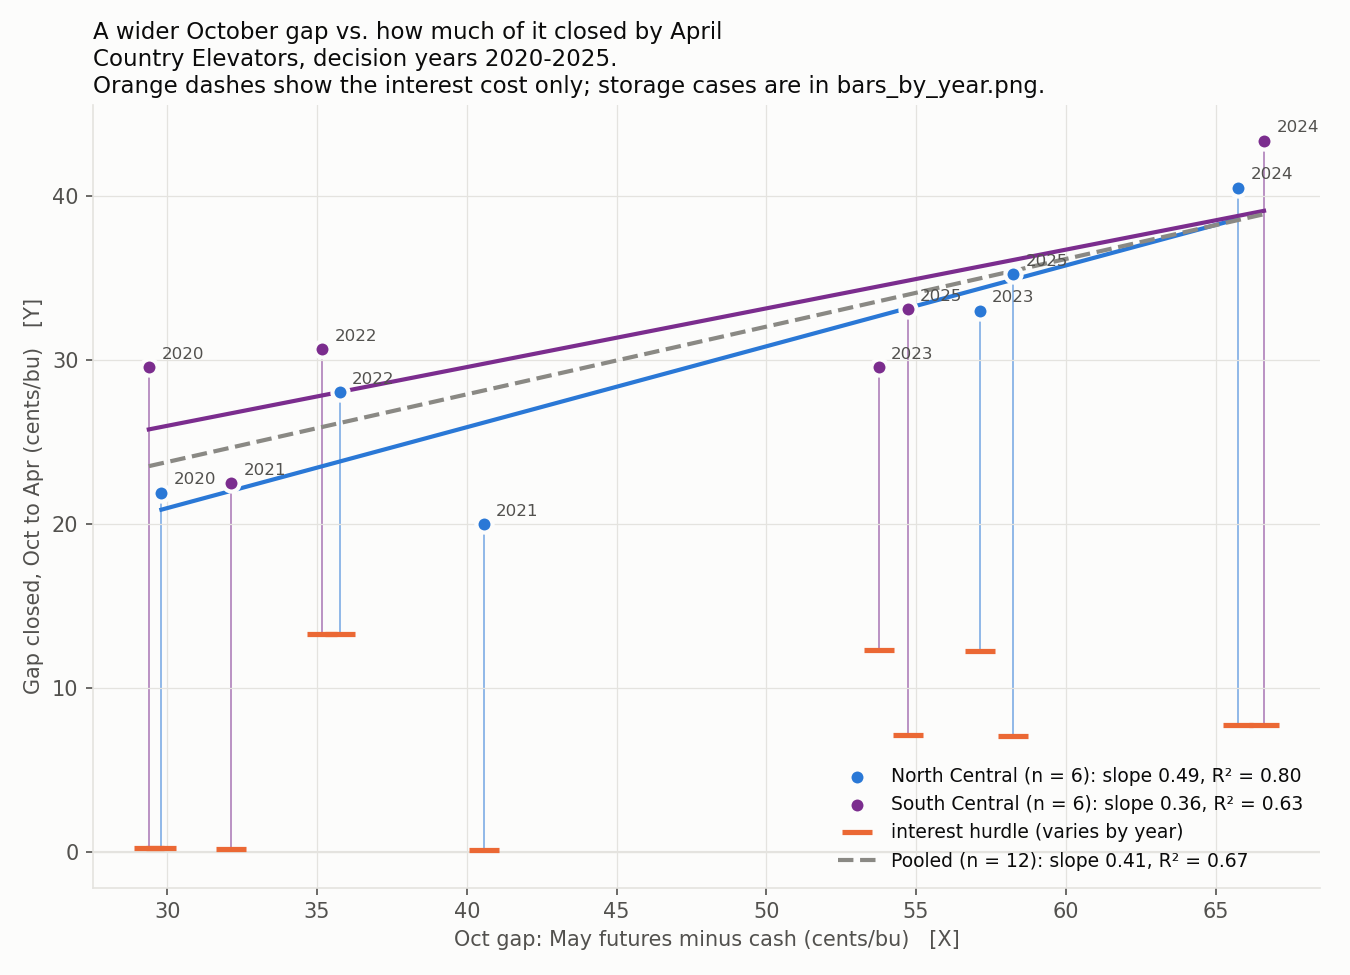

In [22]:
display(Image(filename=str(ROOT / "outputs/scatter_gap.png"), width=720))

### `outputs/bars_by_year.png`

The green bar is the gap closed each year; the three short lines are the hurdles (storage + interest) for the low, mid and
high cases. Storing wins where the bar is **above** a line: always above the low (on-farm) line, almost never above
the mid and high lines. The hurdles jump in 2023, when both the commercial storage rate and the T-bill rate rose.

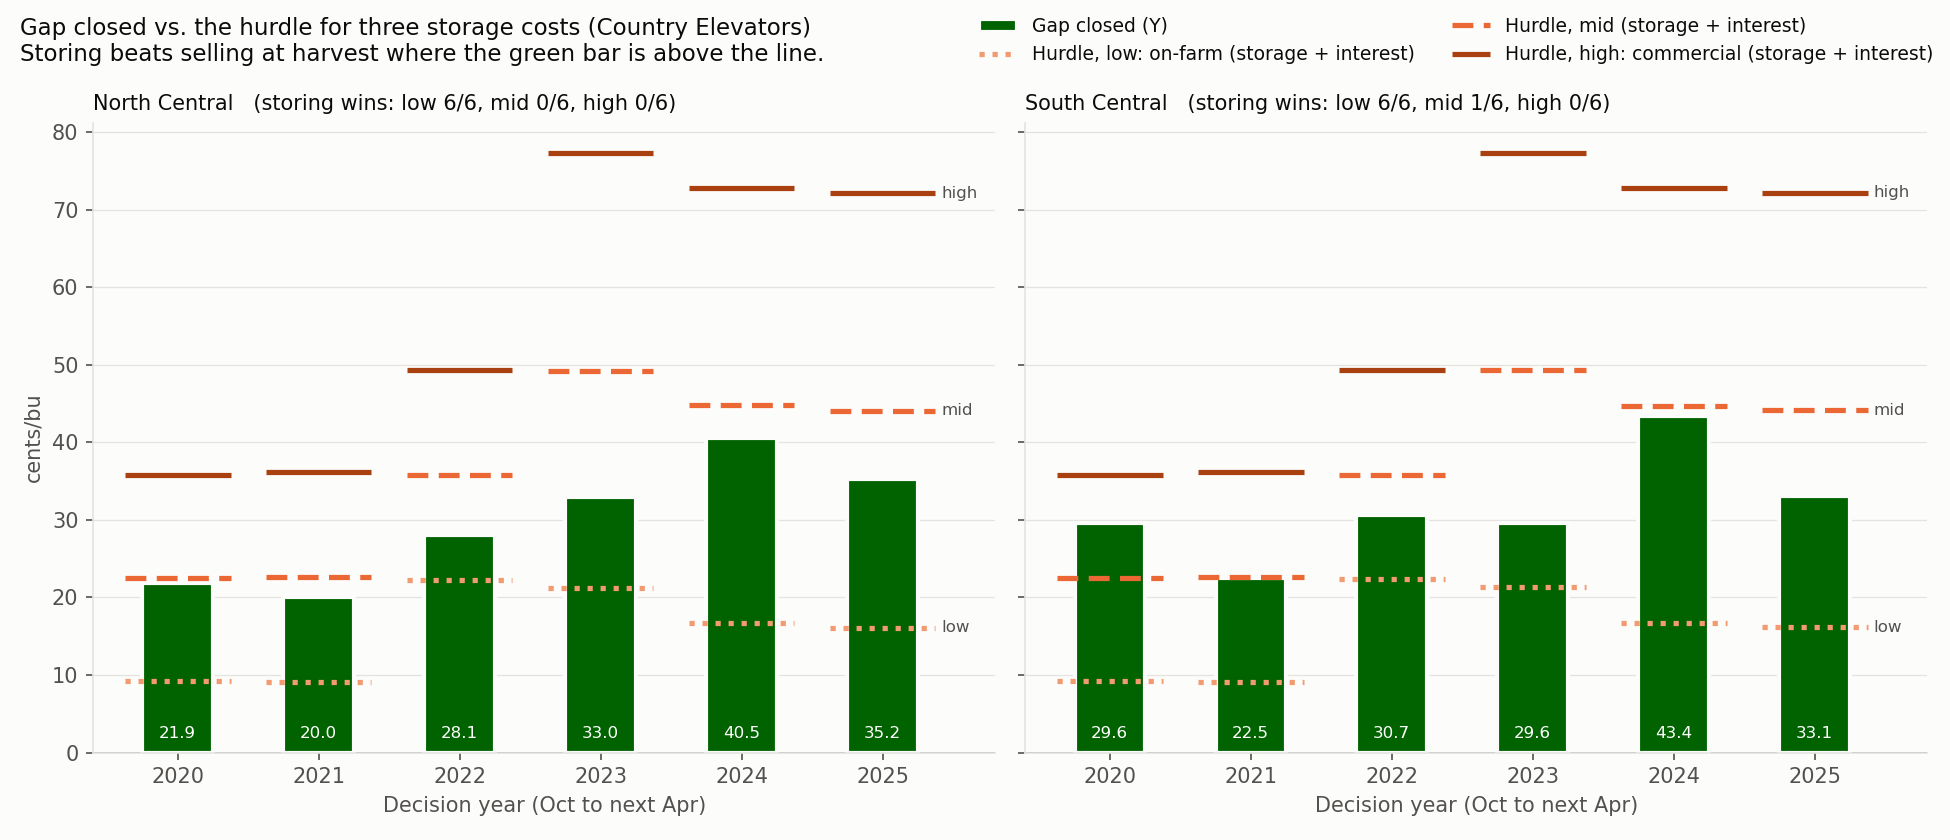

In [23]:
display(Image(filename=str(ROOT / "outputs/bars_by_year.png"), width=900))

*Details:* [processing log: 08_charts.py: charts](../docs/processing_log.md#08_chartspy-charts) (that section still describes the older interest-only bar chart) and [processing log: 2026-11-13: breakeven column, new bar chart, README storage item resolved](../docs/processing_log.md#2026-11-13-breakeven-column-new-bar-chart-readme-storage-item-resolved)

# Part 5: Walk-forward test (`09_walk_forward.py`)

Part 4 fitted lines on **all** years, which is fine for describing the data but cheats as a forecast: in October 2023
nobody knew the 2024 result. The walk-forward test is honest: each test year is predicted using **only earlier years**,
then compared with what really happened. The two regions are pooled (2 rows per year).

| Round | Train on decision years | Training rows | Predict | Last training result known by | Decision date |
|---|---|---|---|---|---|
| 1 | 2020-2022 | 6 | 2023 | Apr 2023 | Oct 13, 2023 |
| 2 | 2020-2023 | 8 | 2024 | Apr 2024 | Oct 15, 2024 |
| 3 | 2020-2024 | 10 | 2025 | Apr 2025 | Oct 15, 2025 |

**Why there is no leakage:** a training year's `gap_closed` is known on Apr 15 of the next calendar year, which is
before the test year's Oct 15. The test row's `gap_oct`, interest and storage cost are all known on its Oct 15 decision date.

**Main code.** `09_walk_forward.py` **lines 39-65**. Two forecasts of `gap_closed` for each test row:
- **regression:** fit `gap_closed ~ gap_oct` on the training rows and apply it to the test row's `gap_oct`;
- **past average:** the mean `gap_closed` of the training rows (the simple baseline).

*Shortened:* fewer stored columns. It uses the gold table built in Part 3, which is identical to the file `09` reads.

In [24]:
TEST_YEARS = [2023, 2024, 2025]
rows, lines = [], []
for rnd, test_year in enumerate(TEST_YEARS, start=1):
    train = gold[gold["decision_year"] < test_year]                       # ONLY earlier years
    test = gold[gold["decision_year"] == test_year]
    assert train["decision_year"].max() < test_year                       # no future data
    slope, intercept = np.polyfit(train["gap_oct_cents"], train["gap_closed_cents"], 1)   # OLS on training rows
    avg = train["gap_closed_cents"].mean()                                # past-average forecast
    lines.append({"round": rnd, "train": f"2020-{test_year - 1}", "n_train": len(train), "test_year": test_year,
                  "intercept": intercept, "slope": slope, "past average": avg})
    for _, r in test.iterrows():
        rows.append({"round": rnd, "test_year": test_year, "region": r["region"],
                     "gap_oct_cents": r["gap_oct_cents"], "actual_gap_closed": r["gap_closed_cents"],
                     "pred_regression": intercept + slope * r["gap_oct_cents"],   # line applied to this Oct gap
                     "pred_past_average": avg,
                     "interest_cents": r["interest_cents"],
                     **{f"storage_{c}_cents": r[f"storage_{c}_cents"] for c in CASES},
                     **{f"net_gain_{c}_cents": r[f"net_gain_{c}_cents"] for c in CASES}})
pred = pd.DataFrame(rows)
display(pd.DataFrame(lines).round(3))                                     # the fitted line in each round

,round,train,n_train,test_year,intercept,slope,past average
0,1,2020-2022,6,2023,34.376,-0.264,25.452
1,2,2020-2023,8,2024,18.491,0.215,26.909
2,3,2020-2024,10,2025,11.253,0.418,29.914


**Forecast accuracy.** `09` **lines 64-65 and 100-101**: error = predicted − actual; MAE (mean absolute error) is the
average size of the miss in cents/bu, ignoring the sign. Lower is better.

In [25]:
pred["err_regression"] = pred["pred_regression"] - pred["actual_gap_closed"]       # predicted - actual
pred["err_past_average"] = pred["pred_past_average"] - pred["actual_gap_closed"]
display(pred[["test_year", "region", "gap_oct_cents", "actual_gap_closed", "pred_regression",
              "err_regression", "pred_past_average", "err_past_average"]].round(2))
mae = {m: pred[f"err_{m}"].abs().mean() for m in ["regression", "past_average"]}
print(f"MAE over {len(pred)} test rows: regression {mae['regression']:.2f}, past average {mae['past_average']:.2f}"
      "   (processing log: 7.16 vs 8.38)")

,test_year,region,gap_oct_cents,actual_gap_closed,pred_regression,err_regression,pred_past_average,err_past_average
0,2023,North Central,57.12,33.00,19.29,-13.71,25.45,-7.55
1,2023,South Central,53.75,29.56,20.18,-9.38,25.45,-4.11
2,2024,North Central,65.75,40.50,32.61,-7.89,26.91,-13.59
3,2024,South Central,66.62,43.37,32.79,-10.58,26.91,-16.46
4,2025,North Central,58.25,35.25,35.62,0.37,29.91,-5.34
5,2025,South Central,54.72,33.12,34.15,1.03,29.91,-3.21


MAE over 6 test rows: regression 7.16, past average 8.38   (processing log: 7.16 vs 8.38)


**Decision rule and scoreboard.** `09` **lines 67-90**. For each storage case c: **store if
forecast − interest > storage_c**, otherwise sell. Every input is known on Oct 15.

- The money result of a test row is its real `net_gain_c` if the strategy stored, and 0 if it sold.
- A **correct call** matches the hindsight best choice: store if the real net gain was > 0.
- Strategies: **always sell** (0 every year, the benchmark), **always store**, **past average**, **regression**.

In [26]:
CALLS = {"always sell": lambda c: pd.Series(False, index=pred.index),     # never store
         "always store": lambda c: pd.Series(True, index=pred.index),     # store every year
         "past average": lambda c: pred["pred_past_average"] - pred["interest_cents"] > pred[f"storage_{c}_cents"],
         "regression": lambda c: pred["pred_regression"] - pred["interest_cents"] > pred[f"storage_{c}_cents"]}
score = []
for c in CASES:
    best = pred[f"net_gain_{c}_cents"] > 0                                # hindsight: storing really paid
    for s, call in CALLS.items():
        store = call(c)                                                   # True = store, False = sell
        net = np.where(store, pred[f"net_gain_{c}_cents"], 0.0)           # money result per test row
        score.append({"storage_case": c, "strategy": s, "times_stored": int(store.sum()),
                      "total_net_gain_cents": net.sum(), "correct_calls": int((store == best).sum())})
score = pd.DataFrame(score)
board = score.assign(result=score["total_net_gain_cents"].map("{:+.1f}".format) + " ("
                     + score["correct_calls"].astype(str) + "/6)")
display(board.pivot(index="storage_case", columns="strategy", values="result").loc[list(CASES), list(CALLS)])
same = np.allclose(score["total_net_gain_cents"], scoreboard_file["total_net_gain_cents"]) and \
       (score["correct_calls"] == scoreboard_file["correct_calls"]).all()
print("matches outputs/scoreboard.csv:", same)

strategy,always sell,always store,past average,regression
storage_case,,,,
low,+0.0 (0/6),+106.5 (6/6),+106.5 (6/6),+86.5 (4/6)
mid,+0.0 (6/6),-61.5 (0/6),+0.0 (6/6),+0.0 (6/6)
high,+0.0 (6/6),-229.5 (0/6),+0.0 (6/6),+0.0 (6/6)


matches outputs/scoreboard.csv: True


*Each cell: total net gain over the 6 test rows, cents/bu (correct calls out of 6).*

**Why round 1 got 2023 wrong.** The first line was fitted on only **6 points** (2020-2022), and its slope came out
**negative** (−0.26): a wider October gap predicted *less* gap closed, the opposite of the full-sample pattern in Part 4.
2023 had a wide October gap (54-57¢), so the line forecast only about 19-20¢, which is below interest + on-farm storage (about 21¢).
The rule said **sell**, but the gap really closed 30-33¢, and storing would have earned +11.8¢ and +8.2¢. The table below
shows those two rows.

In [27]:
r1 = pred[pred["round"] == 1].assign(hurdle_low=lambda d: d["interest_cents"] + d["storage_low_cents"])
r1 = r1.assign(regression_call=np.where(r1["pred_regression"] - r1["interest_cents"] > r1["storage_low_cents"], "store", "sell"),
               past_average_call=np.where(r1["pred_past_average"] - r1["interest_cents"] > r1["storage_low_cents"], "store", "sell"))
display(r1[["test_year", "region", "pred_regression", "pred_past_average", "hurdle_low", "actual_gap_closed",
            "net_gain_low_cents", "regression_call", "past_average_call"]].round(2))
print(f"low-case gain the regression missed in 2023: {r1['net_gain_low_cents'].sum():.2f} cents/bu")

,test_year,region,pred_regression,pred_past_average,hurdle_low,actual_gap_closed,net_gain_low_cents,regression_call,past_average_call
0,2023,North Central,19.29,25.45,21.25,33.00,11.75,sell,store
1,2023,South Central,20.18,25.45,21.34,29.56,8.22,sell,store


low-case gain the regression missed in 2023: 19.97 cents/bu


**Results in short:**
- **Accuracy:** the regression missed by less on average (MAE **7.16** vs **8.38** cents/bu).
- **Money:** in the **low** case, *always store* and *past average* both earned **+106.5¢** over the 6 test rows (6/6
  correct), while the regression earned **+86.5¢** (4/6), because of the 2023 mistake above. In the **mid** and **high**
  cases storing always lost (−61.5¢ and −229.5¢ for always store), and every forecast rule correctly said sell.
- **Lesson:** a more accurate forecast does not guarantee better decisions. Only errors near the hurdle change the call,
  and the regression's one big error happened right there.

*Details:* [processing log: 2026-11-13: 09 walk-forward test (first out-of-sample results)](../docs/processing_log.md#2026-11-13-09-walk-forward-test-first-out-of-sample-results)

# Part 6: Wrap-up

## What this means

- **Storage cost decides the answer, more than forecasting does.** With on-farm storage (about 9¢ for 6 months), a hedged
  storage beat selling at harvest in all 12 region-years. At commercial elevator rates it never did, and at the mid
  cost only once.
- **The October gap did close every year.** The gap between May futures and the local cash price narrowed by 20-43¢
  from October to April, always more than the T-bill interest given up (0.2-13¢). The question is only whether it also covers storage.
- **A simple rule was as good as the model.** "Store if the past average beats the hurdle" made every correct call in the
  test years; the regression had a smaller forecast error but made a costly wrong call in 2023, because its first
  line rested on 6 points.

## Limits and next steps

- **Small sample:** 6 decision years × 2 regions, only 3 test years (6 test rows). Results could easily be luck, and
  round 1's regression was fitted on 6 points. Next: expand to **2010-2026** and to **6 states**, to get roughly 16
  decision years and many more regions.
- **Storage-cost assumptions:** the commercial (high) cost is one Ohio elevator's yearly rate halved, which probably
  understates a 6-month hold (about 68% of the yearly cost, not 50%); the on-farm (low) cost is a single 2016 range,
  the same every year; 2025 high is carried forward from 2024. Shrink, commissions and margin interest are ignored.
- **Apr-vs-Oct basis check:** compare the April basis with the October basis directly, not only their difference, to
  see whether storing gains come from a weak October or a strong April.